Перед запуском убедитесь, что в корне проекта есть файл .env и в нем заполнены выданные вам креды подключения к базам данных и хранилищу

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine

/tmp/ipykernel_18352/670180999.py:2 DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        

In [4]:
# подгружаем .env
load_dotenv()

True

In [5]:
dst_host = os.environ.get('DB_DESTINATION_HOST')
dst_port = os.environ.get('DB_DESTINATION_PORT')
dst_username = os.environ.get('DB_DESTINATION_USER')
dst_password = os.environ.get('DB_DESTINATION_PASSWORD')
dst_db = os.environ.get('DB_DESTINATION_NAME')


In [6]:
# Создадим соединения
dst_conn = create_engine(f'postgresql://{dst_username}:{dst_password}@{dst_host}:{dst_port}/{dst_db}')

In [7]:
pd.options.display.float_format = '{:,.5f}'.format

In [15]:

SQL = """  SELECT
                fl.id AS flat_id,
                b.id AS building_id,
                b.build_year,
                b.building_type_int,
                b.latitude,
                b.longitude,
                b.ceiling_height,
                b.flats_count,
                b.floors_total,
                b.has_elevator,
                fl.floor,
                fl.kitchen_area,
                fl.living_area,
                fl.rooms,
                fl.is_apartment,
                fl.studio,
                fl.total_area,
                fl.price
            FROM flats AS fl
            LEFT JOIN buildings AS b ON fl.building_id = b.id"""
data = pd.read_sql(SQL, dst_conn)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141362 entries, 0 to 141361
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   flat_id            141362 non-null  int64  
 1   building_id        141362 non-null  int64  
 2   build_year         141362 non-null  int64  
 3   building_type_int  141362 non-null  int64  
 4   latitude           141362 non-null  float64
 5   longitude          141362 non-null  float64
 6   ceiling_height     141362 non-null  float64
 7   flats_count        141362 non-null  int64  
 8   floors_total       141362 non-null  int64  
 9   has_elevator       141362 non-null  bool   
 10  floor              141362 non-null  int64  
 11  kitchen_area       141362 non-null  float64
 12  living_area        141362 non-null  float64
 13  rooms              141362 non-null  int64  
 14  is_apartment       141362 non-null  bool   
 15  studio             141362 non-null  bool   
 16  to

In [10]:
data.describe()

,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,floor,kitchen_area,living_area,rooms,total_area,price
count,"141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000","141,362.00000"
mean,"70,680.50000","14,053.66524","1,986.60005",3.23294,55.73006,37.58923,2.75365,251.99323,14.10755,7.46735,9.00158,31.05695,2.12948,62.37464,"19,441,619.95190"
std,"40,807.83871","6,988.83107",22.13641,1.45946,0.10261,0.15012,0.22328,207.33617,6.89805,5.71714,5.26408,23.96864,0.99434,40.29586,"66,269,544.29923"
min,0.00000,1.00000,"1,901.00000",0.00000,55.21146,36.86437,2.00000,1.00000,1.00000,1.00000,0.00000,0.00000,1.00000,11.00000,11.00000
25%,"35,340.25000","8,535.25000","1,969.00000",2.00000,55.65386,37.49176,2.64000,111.00000,9.00000,3.00000,6.10000,19.00000,1.00000,39.30000,"8,900,000.00000"
50%,"70,680.50000","14,332.00000","1,985.00000",4.00000,55.72469,37.58115,2.64000,200.00000,14.00000,6.00000,8.80000,29.40000,2.00000,53.00000,"11,850,000.00000"
75%,"106,020.75000","20,475.00000","2,007.00000",4.00000,55.80732,37.69106,2.80000,324.00000,17.00000,10.00000,10.20000,41.40000,3.00000,72.00000,"16,950,000.00000"
max,"141,361.00000","24,620.00000","2,023.00000",6.00000,56.01103,37.94641,27.00000,"4,455.00000",99.00000,56.00000,203.00000,700.00000,20.00000,960.29999,"9,873,737,728.00000"


## Проверка на дубликаты

In [11]:
# feature_cols = [i for i in data.columns if i not in ['flat_id', 'building_id', 'price']]
# is_duplicated_features = data.duplicated(subset=feature_cols, keep=False)
# print(len(data[is_duplicated_features]))
# data[is_duplicated_features].sort_values(feature_cols)

# data = data[~is_duplicated_features]

Это дубликаты, когда в одном доме несколько одинаковых квартир. Если стоимость разная, то такие квартиры надо убрать, так как таргет итоговый неизвестен, требуется доп. аналитика. Если одинаковая, то или удалить, или отправить в валидационную выборку

In [16]:
feature_cols = [i for i in data.columns if i not in ['flat_id', 
                                                     ]]
is_duplicated_features = data.duplicated(subset=feature_cols, keep="first")
print(len(data[is_duplicated_features]))
data[is_duplicated_features].sort_values(feature_cols)

9116


,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price
54009,54009,3,1901,1,55.75959,37.64649,3.20000,26,4,False,3,0.00000,0.00000,4,False,False,120.00000,60000000
122183,122183,4,1902,1,55.74866,37.65649,3.00000,32,4,False,4,11.00000,48.00000,2,False,False,63.00000,28000000
63594,63594,6,1902,1,55.75458,37.59468,3.20000,15,6,True,5,10.00000,74.00000,3,False,False,100.00000,50000000
107057,107057,10,1902,1,55.76414,37.60258,3.10000,20,22,False,3,0.00000,0.00000,3,False,False,85.00000,55500000
115310,115310,10,1902,1,55.76414,37.60258,3.10000,20,22,False,3,0.00000,0.00000,3,False,False,85.00000,55500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25043,25043,24610,2022,2,55.79005,37.47553,3.10000,184,24,True,18,13.10000,50.50000,3,False,False,90.20000,21440540
100793,100793,24613,2022,2,55.83577,37.49187,2.80000,264,22,True,2,18.00000,0.00000,3,False,False,49.40000,18000000
100937,100937,24613,2022,2,55.83577,37.49187,2.80000,264,22,True,2,18.00000,0.00000,3,False,False,49.40000,18000000
132927,132927,24613,2022,2,55.83577,37.49187,2.80000,264,22,True,2,18.00000,0.00000,3,False,False,49.40000,18000000


In [17]:
data[is_duplicated_features].sort_values(feature_cols)['building_id'].value_counts().sort_values()

building_id
6983      1
7581      1
7592      1
7601      1
7605      1
         ..
23842    19
24035    20
24212    28
24195    35
23996    48
Name: count, Length: 5854, dtype: int64

Вот так можем оставить те дубликаты, в которых в одинаковых домах одинаковая стоимость

In [18]:
feature_cols = [i for i in data.columns if i not in ['flat_id', 'building_id', 'price']]
is_duplicated_features = data.duplicated(subset=feature_cols, keep=False)

data_clean = data[~is_duplicated_features]
data_clean

,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price
0,0,6220,1965,6,55.71711,37.78112,2.64000,84,12,True,9,9.90000,19.90000,1,False,False,35.10000,9500000
1,1,18012,2001,2,55.79485,37.60801,3.00000,97,10,True,7,0.00000,16.60000,1,False,False,43.00000,13500000
2,2,17821,2000,4,55.74004,37.76174,2.70000,80,10,True,9,9.00000,32.00000,2,False,False,56.00000,13500000
3,3,18579,2002,4,55.67202,37.57088,2.64000,771,17,True,1,10.10000,43.10000,3,False,False,76.00000,20000000
4,4,9293,1971,1,55.80881,37.70731,2.60000,208,9,True,3,3.00000,14.00000,1,False,False,24.00000,5200000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141357,141357,22455,2013,4,55.62658,37.31350,2.64000,672,25,True,16,11.00000,18.00000,1,False,False,42.00000,10500000
141358,141358,3162,1960,1,55.72747,37.76868,2.48000,80,5,False,5,5.28000,28.33000,2,False,False,41.11000,7400000
141359,141359,6513,1966,4,55.70432,37.50658,2.64000,72,9,True,7,5.30000,20.00000,1,False,False,31.50000,9700000
141360,141360,23952,2017,4,55.69986,37.93956,2.70000,480,25,True,15,13.80000,33.70000,2,False,False,65.30000,11750000


In [19]:
sum(data_clean.duplicated(subset=feature_cols, keep=False))

0

## Пропущенные значения

In [21]:
data.isnull().sum()

flat_id              0
building_id          0
build_year           0
building_type_int    0
latitude             0
longitude            0
ceiling_height       0
flats_count          0
floors_total         0
has_elevator         0
floor                0
kitchen_area         0
living_area          0
rooms                0
is_apartment         0
studio               0
total_area           0
price                0
dtype: int64

 Так как пропущенных значений нет - не нужно с ними работать

## Очистка от выбросов

Формируем списки с признаками

In [22]:
target_col = ["price"]

id_col = ["building_id", "flat_id"]

bool_col = data.select_dtypes(include=bool).columns

cat_ordinal_col = ["build_year", "floor", "rooms"]

cat_col = ["floors_total", "building_type_int"]

digital_notfilter = ["latitude", "longitude"]

digital_col = list(
    set(data.columns)
    - set(target_col)
    - set(id_col)
    - set(bool_col)
    - set(cat_ordinal_col)
    - set(cat_col)
    - set(digital_notfilter)
)
digital_col

['flats_count', 'kitchen_area', 'ceiling_height', 'total_area', 'living_area']

### Первоначальные графики

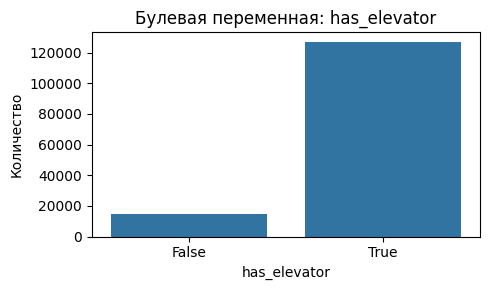

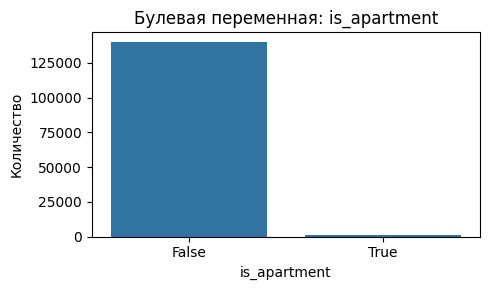

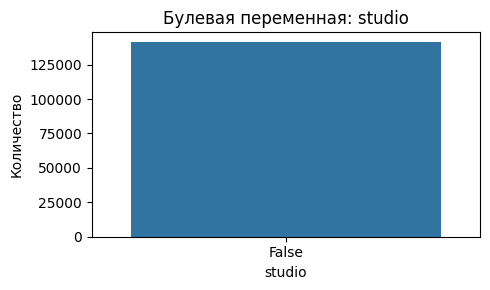

In [23]:
for col in bool_col:
    plt.figure(figsize=(5, 3))
    sns.countplot(x=col, data=data)
    plt.title(f"Булевая переменная: {col}")
    plt.ylabel("Количество")
    plt.tight_layout()
    plt.show()


Вывод: нужно убирать столбец studio, так как в нём только одно значение

In [24]:
data['flats_count'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])

count   141,362.00000
mean        251.99323
std         207.33617
min           1.00000
5%           58.00000
25%         111.00000
50%         200.00000
75%         324.00000
95%         624.00000
max       4,455.00000
Name: flats_count, dtype: float64

[2025-04-26T18:23:02.931+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:03.014+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


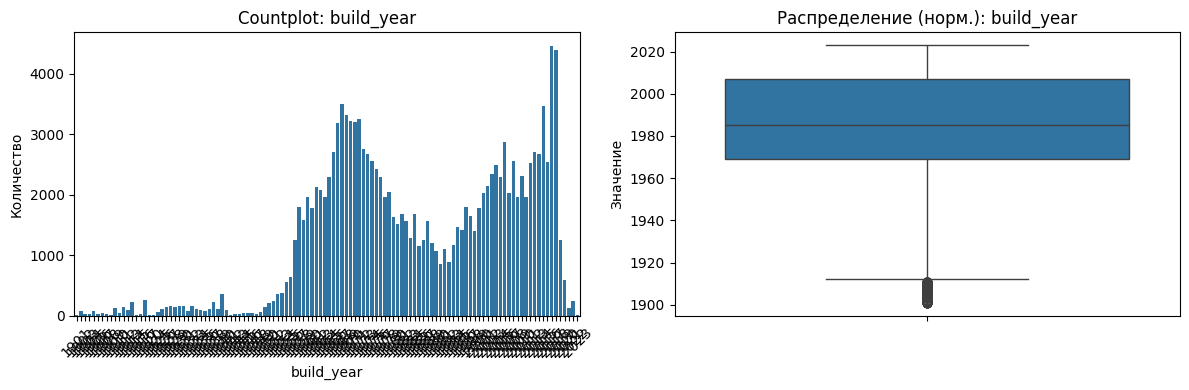

[2025-04-26T18:23:04.271+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:04.335+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


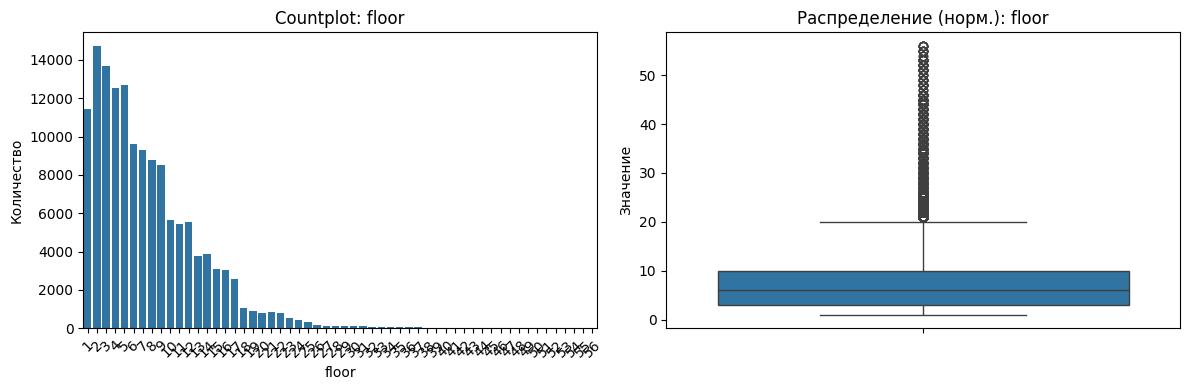

[2025-04-26T18:23:05.196+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:05.265+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


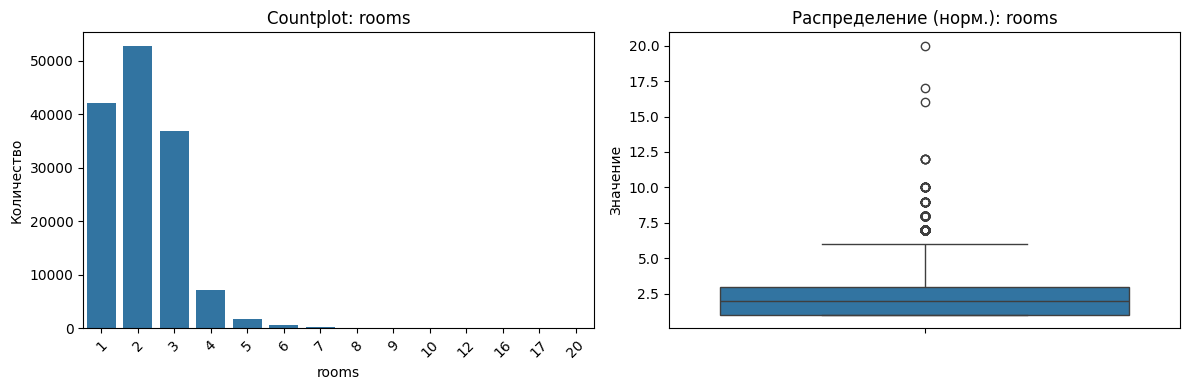

[2025-04-26T18:23:06.051+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:06.107+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


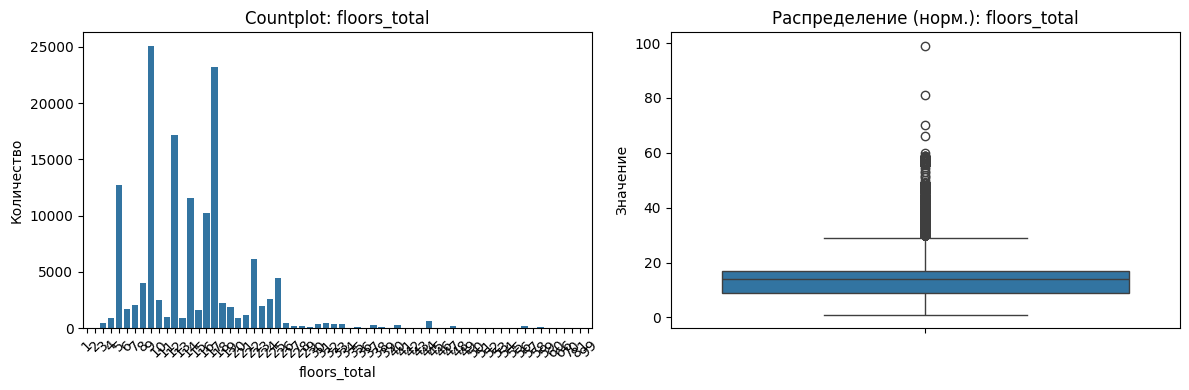

[2025-04-26T18:23:07.007+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:07.073+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


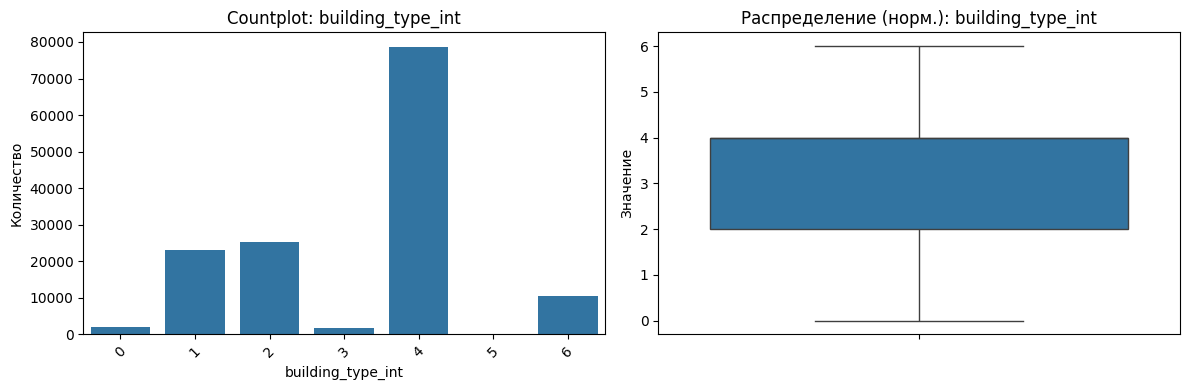

In [25]:
for col in cat_ordinal_col + cat_col:
    sorted_vals = sorted(data[col].dropna().unique())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Countplot
    sns.countplot(ax=axes[0], x=col, data=data, order=sorted_vals)
    axes[0].set_title(f"Countplot: {col}")
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].set_ylabel("Количество")

    # Barplot нормированного распределения
    # normalized_counts = data[col].value_counts(normalize=True).reindex(sorted_vals)
    sns.boxplot(data[col], ax=axes[1])
    axes[1].set_title(f"Распределение (норм.): {col}")
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].set_ylabel("Значение")

    plt.tight_layout()
    plt.show()

План работы с признаками
- 'floors_total' - разбить на три части - по Q3 и Q3 + 1.5*IQR 
- 'building_type_int' - оставляем как есть
- 'build_year' - можно по графику распределений разбить на три части
- 'floor' - разбить на три части - по Q3 и Q3 + 1.5*IQR 
- 'rooms' - разбить на три части - по Q3 и Q3 + 1.5*IQR 

[2025-04-26T18:23:27.542+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:27.601+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


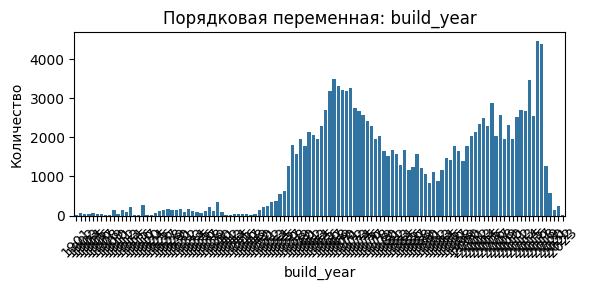

[2025-04-26T18:23:28.437+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:28.496+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


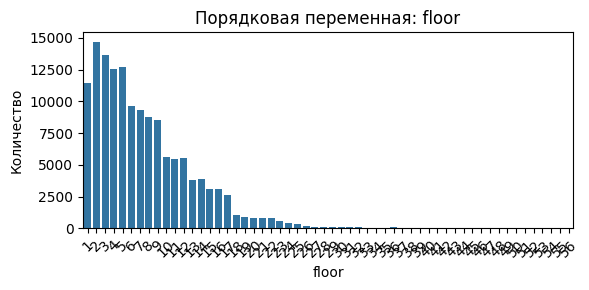

[2025-04-26T18:23:29.007+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:29.067+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


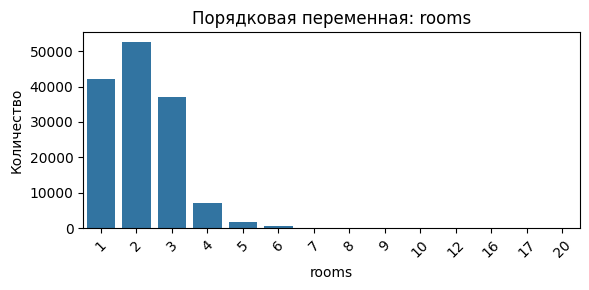

[2025-04-26T18:23:29.387+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:29.448+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


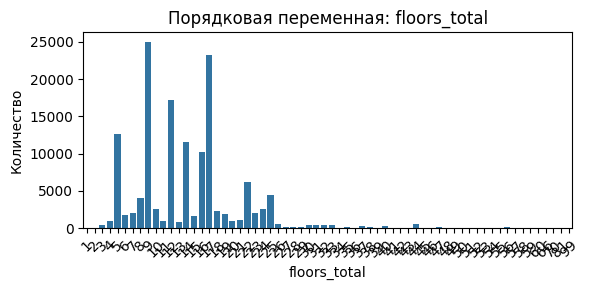

[2025-04-26T18:23:30.621+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:23:30.682+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


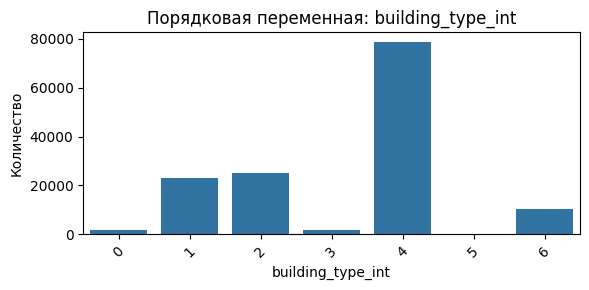

In [26]:
# Порядковые категориальные: сортировка по возрастанию
for col in cat_ordinal_col + cat_col:
    plt.figure(figsize=(6, 3))
    sorted_vals = sorted(data[col].dropna().unique())
    sns.countplot(x=col, data=data, order=sorted_vals)
    plt.title(f"Порядковая переменная: {col}")
    plt.xticks(rotation=45)
    plt.ylabel("Количество")
    plt.tight_layout()
    plt.show()


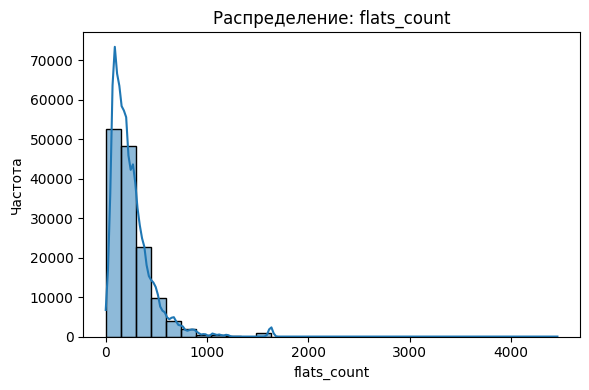

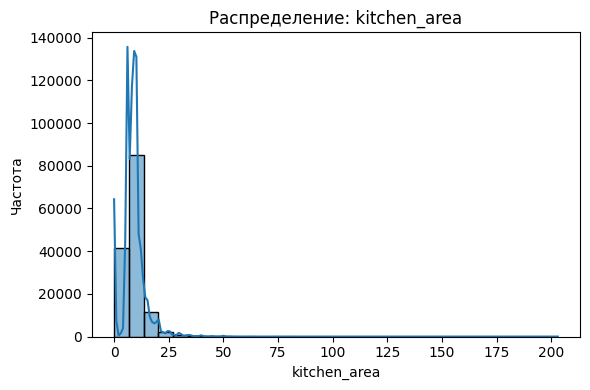

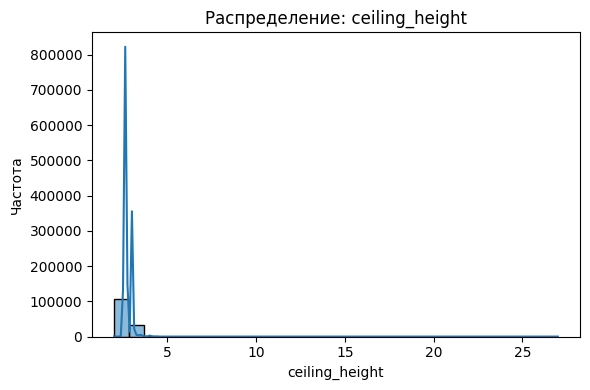

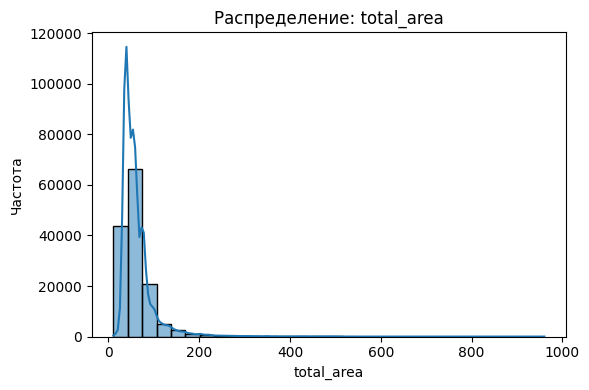

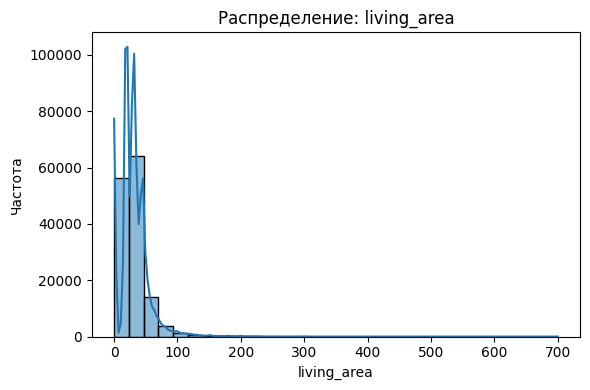

In [27]:
for col in digital_col:
    plt.figure(figsize=(6, 4))
    sns.histplot(data[col], bins=30, kde=True)
    plt.title(f"Распределение: {col}")
    plt.xlabel(col)
    plt.ylabel("Частота")
    plt.tight_layout()
    plt.show()


### Очистка по IQR

In [32]:
def clean_iqr(data, list_col):
    threshold = 1.5
    potential_outliers_id = list()

    for col in list_col:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        margin = threshold * IQR
        lower = Q1 - margin
        upper = Q3 + margin
        potential_outliers_id.extend(
            data[~data[col].between(lower, upper)]["flat_id"].tolist()
        )
        print(
            f"По признаку {col} границы lower {round(lower, 2)} upper {round(upper, 2)}, было удалено: {data[~data[col].between(lower, upper)].shape[0]} flat_id"
        )

    return data[~data["flat_id"].isin(set(potential_outliers_id))]

In [33]:
data = clean_iqr(data, digital_col)

По признаку flats_count границы lower -208.5 upper 643.5, было удалено: 6496 flat_id
По признаку kitchen_area границы lower -0.05 upper 16.35, было удалено: 8076 flat_id
По признаку ceiling_height границы lower 2.4 upper 3.04, было удалено: 9989 flat_id
По признаку total_area границы lower -9.75 upper 121.05, было удалено: 7839 flat_id
По признаку living_area границы lower -14.6 upper 75.0, было удалено: 4962 flat_id


In [162]:
# %pip install geopy

In [163]:
# from geopy.geocoders import Nominatim

# def get_city(lat, lon):
#     geolocator = Nominatim(user_agent="geoapi")
#     location = geolocator.reverse((lat, lon), language="ru")  # язык можно изменить
#     if location and "address" in location.raw:
#         return location.raw["address"].get("city") 
#     return None

# # Пример:
# data['lat_round'] = data['latitude'].round(3)
# data['lon_round'] = data['longitude'].round(3)

# unique_coords = data[['lat_round', 'lon_round']].drop_duplicates().sample(10)
# unique_coords.shape[0]
# # Применяем функцию только к уникальным координатам
# unique_coords['city'] = unique_coords.apply(lambda row: get_city(row['lat_round'], row['lon_round']), axis=1)

# # Мержим обратно в основной датафрейм
# # data = data.merge(unique_coords, on=['latitude', 'longitude'], how='left')

# # data['city'] = data.apply(lambda row: get_city(row['latitude'], row['longitude']), axis=1)


## Target

In [34]:
data[target_col].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.999])

,price
count,"117,609.00000"
mean,"12,838,887.49169"
std,"41,814,096.24299"
min,11.00000
5%,"6,400,000.00000"
25%,"8,550,000.00000"
50%,"11,000,000.00000"
75%,"14,500,000.00000"
95%,"24,300,000.00000"
99.9%,"78,392,000.00001"


In [35]:
data[target_col].min().item()

11

In [36]:
data[data['price'] == data[target_col].min().item()]

,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price
69633,69633,20672,2007,4,55.72404,37.90749,2.78000,368,24,True,9,6.00000,33.00000,2,False,False,42.00000,11


In [37]:
data[data['price'] == data[target_col].max().item()]

,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price
83773,83773,6108,1965,4,55.84266,37.42744,2.64000,72,9,True,6,8.00000,22.00000,2,False,False,37.00000,9799999488


Максимальные и минимальные значения кажутся техническими ошибками, так что есть смысл от них избавиться

<Axes: >

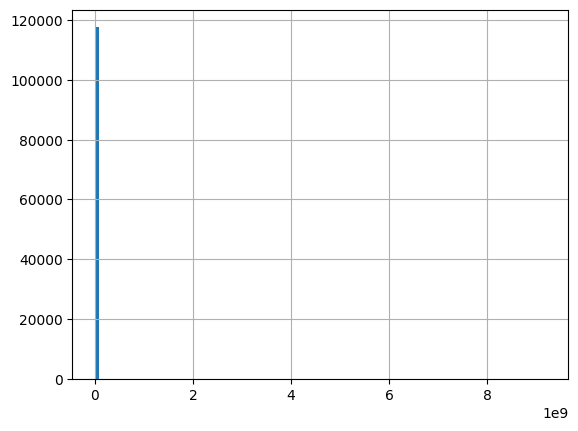

In [38]:
data[(data['price'] != data[target_col].max().item()) & (data['price'] != data[target_col].min().item())]['price'].hist(bins=100)

In [39]:

data[data['price'] == 700_000_000]

,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price
91984,91984,4512,1962,4,55.78643,37.45504,2.48000,80,5,False,3,0.00000,0.00000,2,False,False,45.40000,700000000


### Признак - цена за квадратный метр


Можно отсекать признаки по превышению по цене за квадратный метр

In [40]:
data['price_by_total'] = data['price']  / data['total_area'] 

/tmp/ipykernel_18352/2086897279.py:1 SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

In [41]:
data[['price', 'price_by_total', 'total_area']].sort_values(by='price_by_total', ascending=False).head(60).round(2)

,price,price_by_total,total_area
83773,9799999488,"264,864,851.03000",37.00000
40855,9200000000,"204,444,444.44000",45.00000
79264,3525904640,"36,349,532.37000",97.00000
37521,2500000000,"29,761,904.76000",84.00000
61144,645000000,"16,973,684.21000",38.00000
91984,700000000,"15,418,501.68000",45.40000
96333,401489408,"10,565,510.74000",38.00000
3333,264270000,"6,900,000.14000",38.30000
38993,199500000,"5,115,384.62000",39.00000
135679,143150000,"4,055,240.88000",35.30000


Проведя небольшой анализ реальных цен на площадках по продаже квартир, было выявлено, что квартиры с очень большой стоимостью имеют площадь более 100 метров, значит, что наши значения, где data['total_area'] <100 & data['price_by_total'] > 1_000_000 - это выбросы

In [42]:
data[['price', 'price_by_total', 'total_area']].sort_values(by='price_by_total', ascending=True).head(10).round(2)

,price,price_by_total,total_area
69633,11,0.26000,42.00000
107198,19,0.27000,70.00000
104573,85,1.44000,59.00000
60417,1500,41.67000,36.00000
128961,2000,50.00000,40.00000
21821,3000,50.00000,60.00000
76800,2000,52.63000,38.00000
130229,3000,55.56000,54.00000
60197,2500,59.52000,42.00000
137162,2400,60.00000,40.00000


In [43]:
data["target_outliers"] = np.where(
    ((data["total_area"] < 100) & (data["price_by_total"] > 1_000_000))
    | (data["price_by_total"] < 2),
    True,
    False,
)
display(data["target_outliers"].value_counts())
data = data[~data["target_outliers"]]

/tmp/ipykernel_18352/1583544013.py:1 SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

target_outliers
False    117547
True         62
Name: count, dtype: int64

Удаляем столбец с одним значением и вспомогательные столбцы

In [44]:
data = data.drop(columns=['studio', 'price_by_total', 'target_outliers'])

In [45]:
data

,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,floor,kitchen_area,living_area,rooms,is_apartment,total_area,price
0,0,6220,1965,6,55.71711,37.78112,2.64000,84,12,True,9,9.90000,19.90000,1,False,35.10000,9500000
1,1,18012,2001,2,55.79485,37.60801,3.00000,97,10,True,7,0.00000,16.60000,1,False,43.00000,13500000
2,2,17821,2000,4,55.74004,37.76174,2.70000,80,10,True,9,9.00000,32.00000,2,False,56.00000,13500000
4,4,9293,1971,1,55.80881,37.70731,2.60000,208,9,True,3,3.00000,14.00000,1,False,24.00000,5200000
5,5,23964,2017,4,55.72473,37.74307,2.70000,192,17,True,9,0.00000,0.00000,2,False,51.01000,8490104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141356,141356,9503,1971,4,55.74040,37.83458,2.64000,428,9,True,8,6.00000,42.00000,3,False,64.00000,10800000
141358,141358,3162,1960,1,55.72747,37.76868,2.48000,80,5,False,5,5.28000,28.33000,2,False,41.11000,7400000
141359,141359,6513,1966,4,55.70432,37.50658,2.64000,72,9,True,7,5.30000,20.00000,1,False,31.50000,9700000
141360,141360,23952,2017,4,55.69986,37.93956,2.70000,480,25,True,15,13.80000,33.70000,2,False,65.30000,11750000


## Разделение признаков по бинам

[2025-04-26T18:25:18.465+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:25:18.514+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


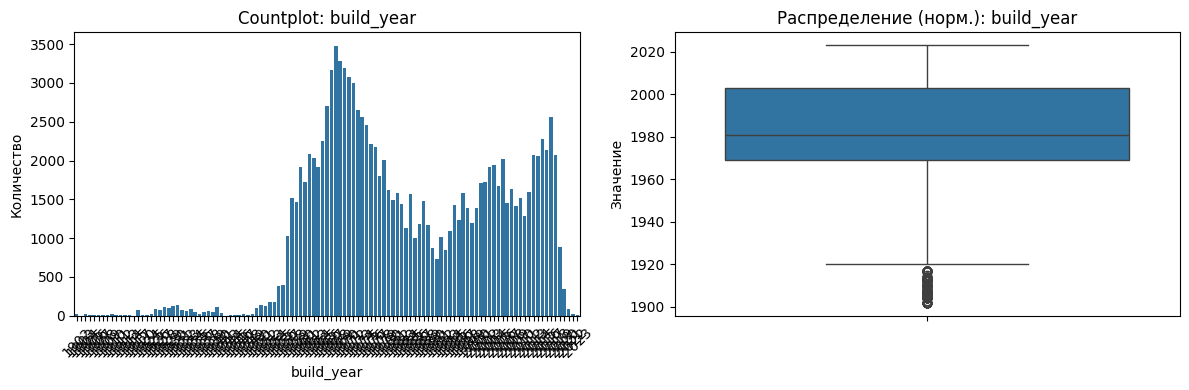

[2025-04-26T18:25:19.877+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:25:19.929+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


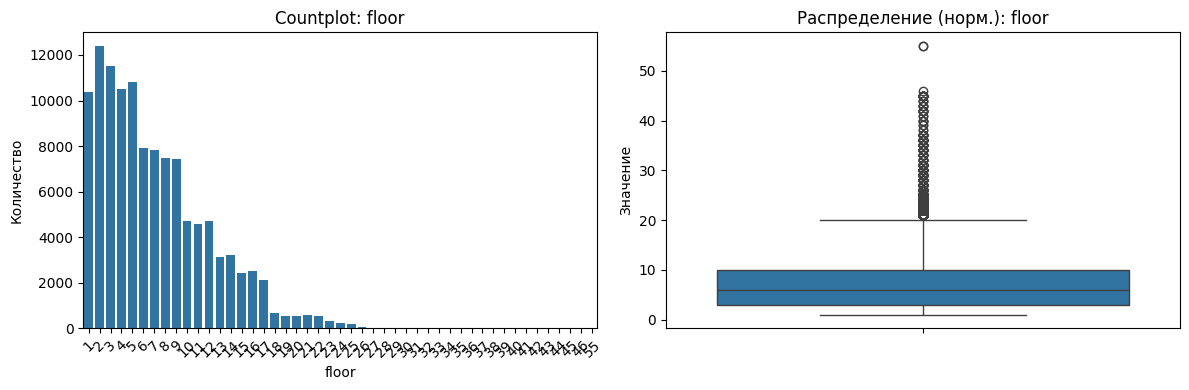

[2025-04-26T18:25:20.737+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:25:20.794+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


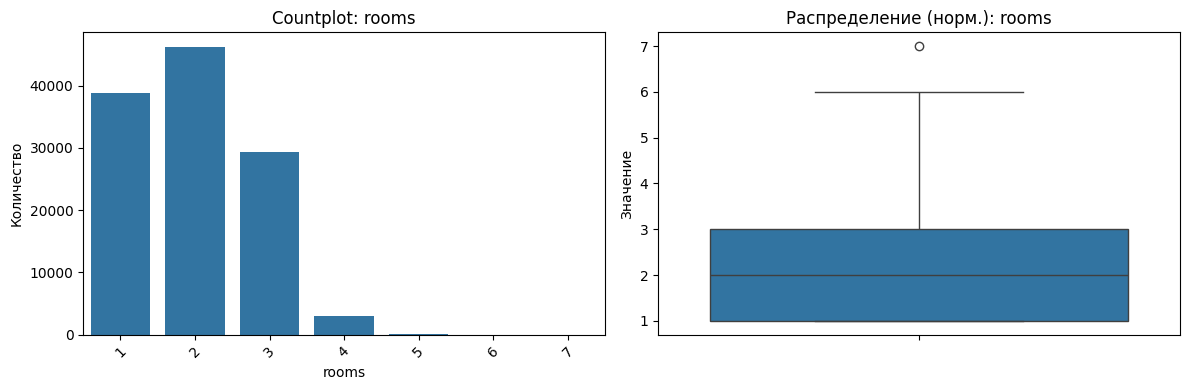

[2025-04-26T18:25:21.380+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:25:21.428+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


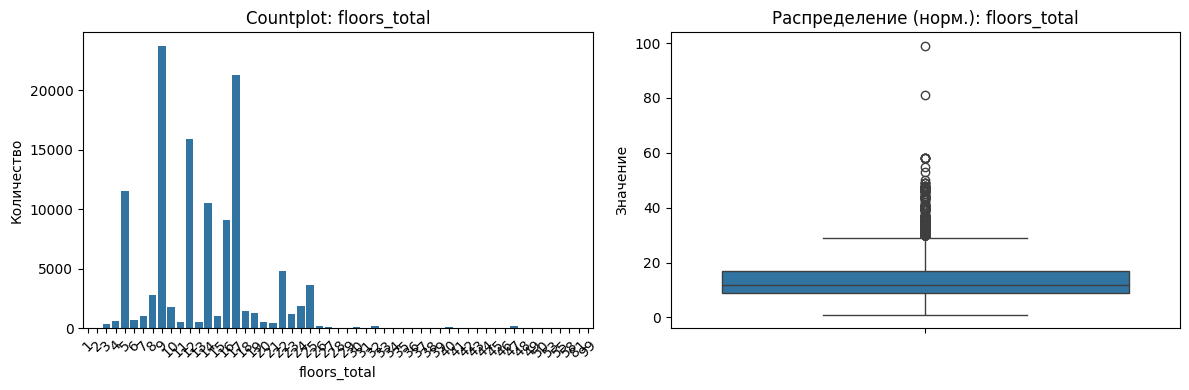

[2025-04-26T18:25:22.226+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[2025-04-26T18:25:22.287+0000] {category.py:223} INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


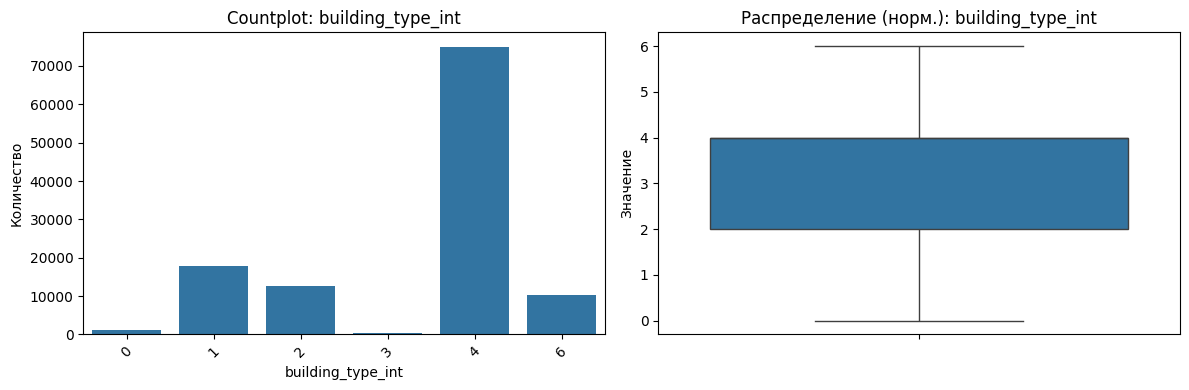

In [46]:
for col in cat_ordinal_col + cat_col:
    sorted_vals = sorted(data[col].dropna().unique())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Countplot
    sns.countplot(ax=axes[0], x=col, data=data, order=sorted_vals)
    axes[0].set_title(f"Countplot: {col}")
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].set_ylabel("Количество")

    # Barplot нормированного распределения
    # normalized_counts = data[col].value_counts(normalize=True).reindex(sorted_vals)
    sns.boxplot(data[col], ax=axes[1])
    axes[1].set_title(f"Распределение (норм.): {col}")
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].set_ylabel("Значение")

    plt.tight_layout()
    plt.show()

In [47]:
def label_discrete_feature(series, bins=None, labels=None, iqr_multiplier=1.5):
    """
    Разбивает дискретную числовую переменную на категории:
    по умолчанию: до Q3, от Q3 до Q3+1.5*IQR, выше Q3+1.5*IQR.
    
    Если bins переданы — используется кастомное разбиение.
    """
    if bins is None:
        q3 = series.quantile(0.75)
        q1 = series.quantile(0.25)
        iqr = q3 - q1
        upper = q3 + iqr_multiplier * iqr
        bins = [float('-inf'), q3, upper, float('inf')]
    
    if labels is None:
        labels = ['low', 'med', 'hig']
    
    return pd.cut(series, bins=bins, labels=labels, right=True, include_lowest=True)


# Автоматическое бинингование
for col in ['floors_total', 'floor', 'rooms']:
    data[col + '_bin'] = label_discrete_feature(data[col])

# Кастомное бинингование для build_year
build_year_bins = [float('-inf'), 1955, 1991, float('inf')]
build_year_labels = ['low', 'med', 'hig']
data['build_year_bin'] = label_discrete_feature(
    data['build_year'], bins=build_year_bins, labels=build_year_labels
)

data.head()


,flat_id,building_id,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator,...,kitchen_area,living_area,rooms,is_apartment,total_area,price,floors_total_bin,floor_bin,rooms_bin,build_year_bin
0,0,6220,1965,6,55.71711,37.78112,2.64000,84,12,True,...,9.90000,19.90000,1,False,35.10000,9500000,low,low,low,med
1,1,18012,2001,2,55.79485,37.60801,3.00000,97,10,True,...,0.00000,16.60000,1,False,43.00000,13500000,low,low,low,hig
2,2,17821,2000,4,55.74004,37.76174,2.70000,80,10,True,...,9.00000,32.00000,2,False,56.00000,13500000,low,low,low,hig
4,4,9293,1971,1,55.80881,37.70731,2.60000,208,9,True,...,3.00000,14.00000,1,False,24.00000,5200000,low,low,low,med
5,5,23964,2017,4,55.72473,37.74307,2.70000,192,17,True,...,0.00000,0.00000,2,False,51.01000,8490104,low,low,low,hig
